## For each dyad, we want to know if the participants' EEG signals are more phase-synchronized during their actual joint trials than during mismatched trials

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import mne
from scipy.signal import hilbert

Load locations

In [6]:
config = json.loads(Path("data/config.json").read_text())

DATASET_PATH = Path(config["dataset_path"]).expanduser()
DERIVATIVES_PATH = Path(config["derivatives_path"]).expanduser()

EPOCHS_DIR = DERIVATIVES_PATH / "epochs"
SUMMARY_PATH = Path("preprocessing_summary.csv")

print("Dataset:", DATASET_PATH)
print("Epochs:", EPOCHS_DIR)
print("Summary exists:", SUMMARY_PATH.exists())

Dataset: /Volumes/untitled/ds007471
Epochs: /Volumes/Untitled/ds007471_derivatives/epochs
Summary exists: True


Get preprocessing results

In [7]:
summary = pd.read_csv(SUMMARY_PATH)

print(summary.shape)
print(summary.columns.tolist())
summary.head()

(32, 7)
['sub', 'boundary', 'practice', 'real', 'complete', 'duet', 'constant_pitch']


,sub,boundary,practice,real,complete,duet,constant_pitch
0,sub-01,S1,6,57,39,19,20
1,sub-02,S1,6,58,37,19,18
2,sub-03,S107 fallback,6,56,40,20,20
3,sub-04,S1,6,57,37,19,18
4,sub-05,S1,6,56,39,20,19


Calculate Matrix containing real pairings as diagonal and chance levels off-diagonal

In [ ]:
plv_shuffled_matrices = {}

for subname in summary["sub"]:

    epochs_R = mne.read_epochs(
        EPOCHS_DIR / f"{subname}_R_long-epo.fif",
        preload=True
    )

    epochs_L = mne.read_epochs(
        EPOCHS_DIR / f"{subname}_L_long-epo.fif",
        preload=True
    )

    # Bandpass filter (theta)
    theta_R = epochs_R.copy().filter(
        l_freq=4,
        h_freq=8,
        picks="eeg"
    )

    theta_L = epochs_L.copy().filter(
        l_freq=4,
        h_freq=8,
        picks="eeg"
    )

    # Extract analytic signal
    theta_R.apply_hilbert(envelope=False)
    theta_L.apply_hilbert(envelope=False)

    # Crop to time window of interest
    theta_R.crop(tmin=4.5, tmax=12.5)
    theta_L.crop(tmin=4.5, tmax=12.5)

    # Extract instantaneous phase
    phase_R = np.angle(theta_R.get_data())
    phase_L = np.angle(theta_L.get_data())

    n_trials = phase_R.shape[0]
    T = phase_R.shape[-1]
    
    # Convert all trials to complex unit vectors
    U_R = np.exp(1j * phase_R)
    U_L = np.exp(1j * phase_L)

    # Matrix to store cross-trial PLV values
    M = np.zeros((n_trials, n_trials))

    for i in range(n_trials):
        for j in range(n_trials):

            cross_phase = U_R[i] @ U_L[j].conj().T

            plv_matrix = np.abs(cross_phase) / T

            M[i, j] = plv_matrix.mean()
            
    # Store matrix for this subject
    plv_shuffled_matrices[subname] = M

We now have this matrix for every subject:
![image.png](plv-matrix.png)

Visualize M for one subject

Reading /Volumes/Untitled/ds007471_derivatives/epochs/sub-10_R_long-epo.fif ...
    Found the data of interest:
        t =    2000.00 ...   15000.00 ms
        0 CTF compensation matrices available
Adding metadata with 1 columns
40 matching events found
No baseline correction applied
0 projection items activated
Reading /Volumes/Untitled/ds007471_derivatives/epochs/sub-10_L_long-epo.fif ...
    Found the data of interest:
        t =    2000.00 ...   15000.00 ms
        0 CTF compensation matrices available
Adding metadata with 1 columns
40 matching events found
No baseline correction applied
0 projection items activated


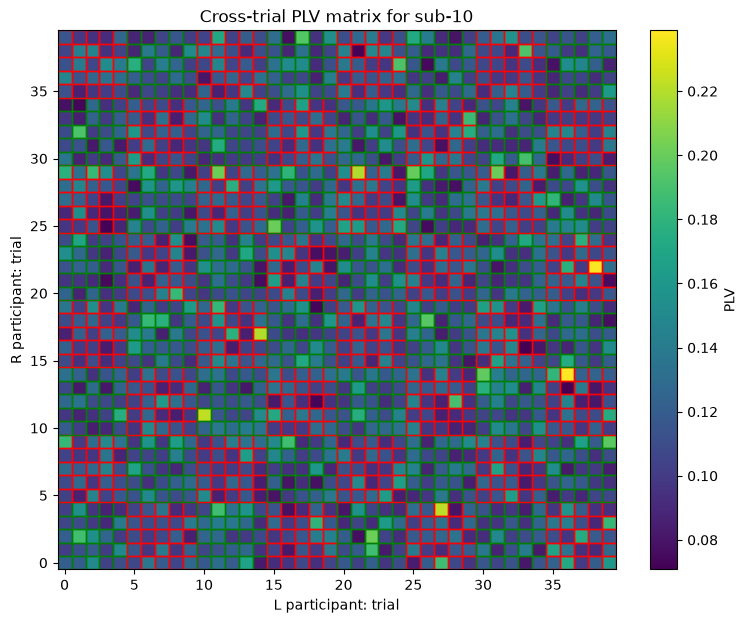

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
subname = "sub-01"

epochs_R = mne.read_epochs(
    EPOCHS_DIR / f"{subname}_R_long-epo.fif",
    preload=True
)

# Get indices of duet trials
duet_indices = np.where(
    epochs_R.metadata["condition"] == "duet"
)[0]

M = plv_shuffled_matrices[subname]

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(M, aspect="auto", origin="lower")

plt.colorbar(im, label="PLV")
ax.set_xlabel("L participant: trial")
ax.set_ylabel("R participant: trial")
ax.set_title(f"Cross-trial PLV matrix for {subname}")

# Draw red boxes around duet trials on the diagonal
for i in duet_indices:
    rect = patches.Rectangle(
        (i - 0.5, i - 0.5),
        1,
        1,
        linewidth=1.5,
        edgecolor="red",
        facecolor="none"
    )
    ax.add_patch(rect)

plt.show()

In [47]:
import numpy as np
import pandas as pd
import mne

results = []

for subname in summary["sub"]:

    # Load condition labels
    epochs_R = mne.read_epochs(
        EPOCHS_DIR / f"{subname}_R_long-epo.fif",
        preload=False
    )

    conditions = epochs_R.metadata["condition"].to_numpy()

    # Retrieve cross-trial matrix
    M = plv_shuffled_matrices[subname]

    # Process each condition
    for condition in ["duet", "constant_pitch"]:

        # Find trial indices
        idx = np.where(conditions == condition)[0]

        # Extract condition-specific matrix
        M_condition = M[np.ix_(idx, idx)]

        # Real PLV: diagonal
        real = np.diag(M_condition)

        # Shuffled PLV: row mean excluding diagonal
        shuffled = (
            M_condition.sum(axis=1) - real
        ) / (len(real) - 1)

        # Excess PLV
        excess = real - shuffled

        # Store results
        results.append({
            "subject": subname,
            "condition": condition,
            "n_trials": len(idx),
            "real_PLV": real.mean(),
            "shuffled_PLV": shuffled.mean(),
            "excess_PLV": excess.mean()
        })

    print(f"Processed {subname}")

# Create DataFrame
results_df = pd.DataFrame(results)

# Save CSV
results_df.to_csv("plv_condition_results.csv", index=False)

results_df

Reading /Volumes/Untitled/ds007471_derivatives/epochs/sub-01_R_long-epo.fif ...
    Found the data of interest:
        t =    2000.00 ...   15000.00 ms
        0 CTF compensation matrices available
Adding metadata with 1 columns
39 matching events found
No baseline correction applied
0 projection items activated
Processed sub-01
Reading /Volumes/Untitled/ds007471_derivatives/epochs/sub-02_R_long-epo.fif ...
    Found the data of interest:
        t =    2000.00 ...   15000.00 ms
        0 CTF compensation matrices available
Adding metadata with 1 columns
37 matching events found
No baseline correction applied
0 projection items activated
Processed sub-02
Reading /Volumes/Untitled/ds007471_derivatives/epochs/sub-03_R_long-epo.fif ...
    Found the data of interest:
        t =    2000.00 ...   15000.00 ms
        0 CTF compensation matrices available
Adding metadata with 1 columns
40 matching events found
No baseline correction applied
0 projection items activated
Processed sub-03
Read

,subject,condition,n_trials,real_PLV,shuffled_PLV,excess_PLV
0,sub-01,duet,19,0.114369,0.116048,-0.001678
1,sub-01,constant_pitch,20,0.117174,0.117632,-0.000458
2,sub-02,duet,19,0.102924,0.113267,-0.010342
3,sub-02,constant_pitch,18,0.114239,0.117166,-0.002927
4,sub-03,duet,20,0.125602,0.119862,0.005740
...,...,...,...,...,...,...
59,sub-30,constant_pitch,20,0.120890,0.116872,0.004018
60,sub-31,duet,19,0.123891,0.120646,0.003245
61,sub-31,constant_pitch,19,0.109926,0.119408,-0.009482
62,sub-32,duet,20,0.130709,0.123458,0.007251
